# Customer Feedback Analysis and Automated Response

## Business Objective
A retail company receives thousands of reviews and tickets every week. This notebook automates the first-level triage:

1. Load and clean the review data (Pandas).
2. Filter **critical** reviews (1 and 2 stars) with plain Python rules - no Machine Learning.
3. Find the most common complaint keywords with `collections.Counter`.
4. Pick the 3 most severe and detailed complaints.
5. Use Generative AI (OpenAI, or Hugging Face through the same client) to draft a short, empathetic apology email for each.

**Dataset:** Amazon product reviews (Kaggle - "Amazon Review Data Web Scrapping"), used as a proxy for customer-support tickets.

## Pipeline
```
Raw CSV -> Missing values / duplicates -> Text normalisation -> Critical filter (1-2 stars)
        -> Complaint keywords -> Severity ranking (top 3) -> LLM prompt -> Email drafts -> Exports
```

**How to run:** see `README.md`. Set `OPENAI_API_KEY` (or `LLM_PROVIDER=huggingface` with `HF_TOKEN`). Without a key the notebook still runs end-to-end, but emails come from a clearly labelled *fallback template* instead of the LLM.

## 1. Setup and Configuration

In [7]:
# import sys
# print(sys.executable)

In [8]:
# import sys
# !{sys.executable} -m pip install openai

In [9]:
# %pip install -q -U openai httpx pydantic typing_extensions anyio

In [10]:
# import openai
# print(openai.__version__)

In [11]:

import os
from getpass import getpass

# ---- LLM provider setup (the only place you need to change) ----
# "openai"      -> OpenAI API          (key read from OPENAI_API_KEY)
# "huggingface" -> Hugging Face router (key read from HF_TOKEN); same OpenAI-compatible client
LLM_PROVIDER = os.environ.get("LLM_PROVIDER", "groq").strip().lower()

PROVIDER_SETTINGS = {
    "openai": {
        "key_env": "OPENAI_API_KEY",
        "base_url": None,                                  # default OpenAI endpoint
        "model": "gpt-5-mini",
    },
    "huggingface": {
        "key_env": "HF_TOKEN",
        "base_url": "https://router.huggingface.co/v1",    # OpenAI-compatible endpoint
        "model": "openai/gpt-oss-120b",
    },
    "groq": {
        "key_env": "GROQ_API_KEY",
        "base_url": "https://api.groq.com/openai/v1",      # OpenAI-compatible endpoint
        "model": "openai/gpt-oss-120b",
    },
}

if LLM_PROVIDER not in PROVIDER_SETTINGS:
    raise ValueError(f"LLM_PROVIDER must be one of {list(PROVIDER_SETTINGS)}, got {LLM_PROVIDER!r}")

_settings = PROVIDER_SETTINGS[LLM_PROVIDER]
LLM_BASE_URL = _settings["base_url"]
LLM_MODEL = os.environ.get("LLM_MODEL", _settings["model"])    # override the model without editing code
LLM_TEMPERATURE = None   # None = model default (required by the gpt-5 family); e.g. 0.4 for models that allow it

# Never hard-code keys. Read from the environment, else ask securely.
LLM_API_KEY = os.environ.get(_settings["key_env"], "").strip()
PROMPT_FOR_KEY = True    # set False to skip the prompt and use the fallback template
if not LLM_API_KEY and PROMPT_FOR_KEY:
    try:
        LLM_API_KEY = getpass(f"Enter your {_settings['key_env']} (press Enter to use fallback emails): ").strip()
    except Exception:    # non-interactive run: no prompt available
        LLM_API_KEY = ""

print("LLM provider :", LLM_PROVIDER)
print("LLM model    :", LLM_MODEL)
print("API key found:", bool(LLM_API_KEY))

LLM provider : groq
LLM model    : openai/gpt-oss-120b
API key found: True


In [12]:
from collections import Counter
from pathlib import Path
import json
import os
import re
import time

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

# ---- Configuration (change here only) ----
# Path to the CSV. Set the REVIEWS_CSV environment variable, or place the file in ./data/
DATA_PATH = Path(
    r"C:\Users\nazmi\Downloads\3549704\Amazon Review Data Web Scrapping - Amazon Review Data Web Scrapping.csv"
)
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# LLM provider, model and API key are configured in the cell above (never hard-code keys).
MIN_WORDS_FOR_TOP_CASES = 30     # "detailed" review = at least this many meaningful words

print("API key detected:", bool(LLM_API_KEY))

API key detected: True


## 2. Data Loading and Overview

In [13]:
print("LLM provider:", LLM_PROVIDER)
print("API key detected:", bool(LLM_API_KEY))
print("LLM model:", LLM_MODEL)

LLM provider: groq
API key detected: True
LLM model: openai/gpt-oss-120b


In [14]:
import os
print(os.getcwd())
print("llm_structured.py" in os.listdir())   # must print True

C:\Users\nazmi
True


In [15]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Place the CSV in ./data/ or set the REVIEWS_CSV environment variable."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"Rows: {len(df_raw):,} | Columns: {df_raw.columns.tolist()}")
display(df_raw.head())

Rows: 60,889 | Columns: ['Unique_ID', 'Category', 'Review_Header', 'Review_text', 'Rating', 'Own_Rating']


,Unique_ID,Category,Review_Header,Review_text,Rating,Own_Rating
0,136040,smartTv,Nice one,I liked it,5,Positive
1,134236,mobile,Huge battery life with amazing display,I bought the phone on Amazon and been using my...,5,Positive
2,113945,books,Four Stars,"Awesome book at reasonable price, must buy ......",4,Positive
3,168076,smartTv,Nice quality,good,5,Positive
4,157302,books,Nice book,"The book is fine,not bad,contains nice concept...",3,Neutral


In [16]:
# Missing values, rating distribution and category distribution in one place
missing_summary = df_raw.isna().sum().rename("missing_count").to_frame()
missing_summary["missing_percentage"] = (missing_summary["missing_count"] / len(df_raw) * 100).round(2)
rating_summary = df_raw["Rating"].value_counts().sort_index().rename_axis("rating").reset_index(name="review_count")
category_summary = df_raw["Category"].value_counts().rename_axis("category").reset_index(name="review_count")

print("Missing values:");       display(missing_summary)
print("Rating distribution:");  display(rating_summary)
print("Category distribution:"); display(category_summary)

Missing values:


,missing_count,missing_percentage
Unique_ID,0,0.00
Category,0,0.00
Review_Header,5,0.01
Review_text,32,0.05
Rating,0,0.00
Own_Rating,0,0.00


Rating distribution:


,rating,review_count
0,1,6979
1,2,2108
2,3,4366
3,4,12976
4,5,34460


Category distribution:


,category,review_count
0,mobile,22749
1,mobile accessories,14811
2,smartTv,14624
3,refrigerator,4791
4,books,3914


## 3. Data Cleaning
**Approach**
- Missing `Review_Header` / `Review_text` are filled with empty strings; the header and text are combined into one `customer_message`.
- Text normalisation: lowercase, curly apostrophes fixed, contractions expanded (so *"doesn't work"* becomes *"does not work"* and negation is preserved), special characters removed, extra spaces collapsed.
- Rows whose cleaned text is empty (e.g. blank or emoji-only / non-English reviews) are dropped.
- Exact duplicates (same header + text + rating) are dropped, because repeated copies would inflate keyword counts.

In [17]:
# Expanded contractions (curly apostrophes are converted to straight ones first)
CONTRACTIONS = {
    "can't": "cannot", "won't": "will not", "doesn't": "does not", "didn't": "did not",
    "isn't": "is not", "wasn't": "was not", "couldn't": "could not", "wouldn't": "would not",
    "don't": "do not", "shouldn't": "should not", "haven't": "have not", "hasn't": "has not",
    "hadn't": "had not", "aren't": "are not", "weren't": "were not",
    "it's": "it is", "i'm": "i am", "i've": "i have", "you're": "you are", "they're": "they are",
}
# One compiled regex instead of one regex per contraction
CONTRACTION_RE = re.compile(r"\b(" + "|".join(re.escape(c) for c in CONTRACTIONS) + r")\b", re.IGNORECASE)


def normalize_text(text: str) -> str:
    """Lowercase, expand contractions, strip special characters, collapse spaces."""
    text = str(text or "").replace("\u2019", "'").replace("\u2018", "'").strip().lower()
    text = CONTRACTION_RE.sub(lambda m: CONTRACTIONS[m.group(0).lower()], text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


assert normalize_text("The phone doesn\u2019t charge properly!!!") == "the phone does not charge properly"
print(normalize_text("The phone doesn't charge properly!!!"))

the phone does not charge properly


In [18]:
df = df_raw.copy()
df["Review_Header"] = df["Review_Header"].fillna("").astype(str)
df["Review_text"] = df["Review_text"].fillna("").astype(str)
df["Category"] = df["Category"].fillna("unknown").astype(str)

# Combine header + body (strip avoids a leading ". " when the header is empty)
df["customer_message"] = (df["Review_Header"].str.strip() + ". " + df["Review_text"].str.strip()).str.strip(" .")
df["clean_review"] = df["customer_message"].map(normalize_text)

rows_start = len(df)
df = df[df["clean_review"].ne("")].copy()
rows_empty = rows_start - len(df)

df = df.drop_duplicates(subset=["Review_Header", "Review_text", "Rating"]).reset_index(drop=True)
rows_dupes = rows_start - rows_empty - len(df)

cleaning_summary = pd.DataFrame({
    "metric": ["Original rows", "Removed: empty after cleaning", "Removed: exact duplicates", "Cleaned rows"],
    "value": [len(df_raw), rows_empty, rows_dupes, len(df)],
})
display(cleaning_summary)
display(df[["customer_message", "clean_review"]].head())

,metric,value
0,Original rows,60889
1,Removed: empty after cleaning,83
2,Removed: exact duplicates,5072
3,Cleaned rows,55734


,customer_message,clean_review
0,Nice one. I liked it,nice one i liked it
1,Huge battery life with amazing display. I boug...,huge battery life with amazing display i bough...
2,"Four Stars. Awesome book at reasonable price, ...",four stars awesome book at reasonable price mu...
3,Nice quality. good,nice quality good
4,"Nice book. The book is fine,not bad,contains n...",nice book the book is fine not bad contains ni...


## 3b. Exploratory Data Analysis (EDA)
Before any rule-based analysis, we look at the data itself. Each chart answers one question, and the takeaway under it is **computed from the data**, so the numbers can never drift from the charts. These findings justify the design choices used later (filtering, minimum review length, deduplication).

| Q | Question | Chart |
|---|---|---|
| 1 | How are ratings distributed? | Bar chart |
| 4 | How many rows did each cleaning step remove? | Horizontal bar chart |
| 5 | Did cleaning distort any rating group? | Removal rate by rating |
| 7 | How long are reviews of each rating? | Box plot |
| 8 | How many critical reviews are detailed enough to personalize? | Histogram |
| 10 | Which categories attract the most criticism? | Stacked and bar charts |
| 13 | Which words are most frequent in critical reviews before any filtering? | Top-15 bar charts |

In [19]:
import numpy as np

from IPython.display import Markdown, display


plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
})

RATING_COLORS = ["#c0392b", "#e67e22", "#95a5a6", "#5dade2", "#2874a6"]   # 1 to 5 stars
SENTIMENT_ORDER = ["Critical (1-2 stars)", "Neutral (3 stars)", "Positive (4-5 stars)"]
SENTIMENT_COLORS = ["#c0392b", "#95a5a6", "#2e86c1"]

# Working copy with the two helper columns used by several charts.
eda = df.copy()
eda["word_count"] = eda["clean_review"].str.split().str.len()
eda["sentiment_group"] = pd.cut(eda["Rating"], bins=[0, 2, 3, 5], labels=SENTIMENT_ORDER)
CRITICAL = SENTIMENT_ORDER[0]


def takeaway(text: str) -> None:
    """Show a short, data-driven conclusion under a chart."""
    display(Markdown(f"**Takeaway:** {text}"))


print(f"EDA data ready: {len(eda):,} cleaned reviews")

EDA data ready: 55,734 cleaned reviews


#### Q1. Rating distribution (original data)

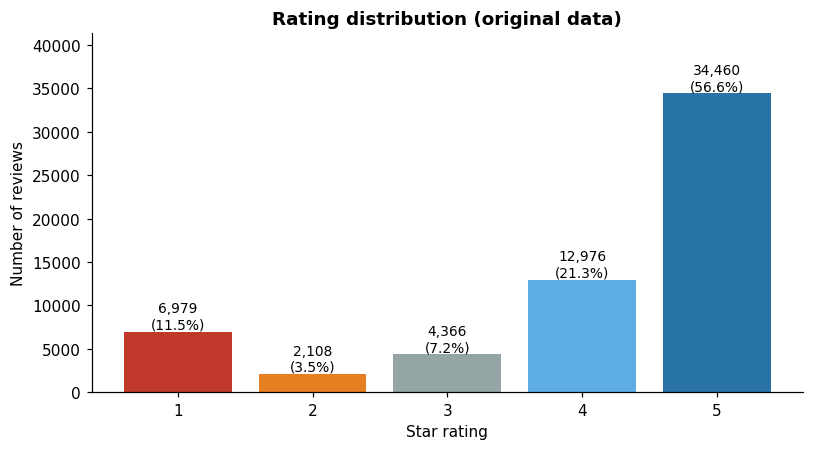

**Takeaway:** The data is heavily skewed: 5-star reviews are the largest group (56.6%), while only 9,087 reviews (14.9%) are critical (1-2 stars). Support teams therefore need automatic triage to find the few reviews that matter.

In [20]:
rating_counts = df_raw["Rating"].value_counts().sort_index()
rating_pct = rating_counts / rating_counts.sum() * 100
stars = [int(r) for r in rating_counts.index]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
bars = ax.bar([str(s) for s in stars], rating_counts.values, color=[RATING_COLORS[s - 1] for s in stars])
for bar, count, pct in zip(bars, rating_counts.values, rating_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{count:,}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=9)
ax.set_title("Rating distribution (original data)")
ax.set_xlabel("Star rating")
ax.set_ylabel("Number of reviews")
ax.set_ylim(0, rating_counts.max() * 1.2)
plt.tight_layout()
plt.show()

critical_raw = int(rating_counts.reindex([1, 2], fill_value=0).sum())
top_star = int(rating_counts.idxmax())
takeaway(
    f"The data is heavily skewed: {top_star}-star reviews are the largest group "
    f"({rating_pct.max():.1f}%), while only {critical_raw:,} reviews ({critical_raw / len(df_raw):.1%}) are "
    "critical (1-2 stars). Support teams therefore need automatic triage to find the few reviews that matter."
)

### Q4. What did each cleaning step remove?

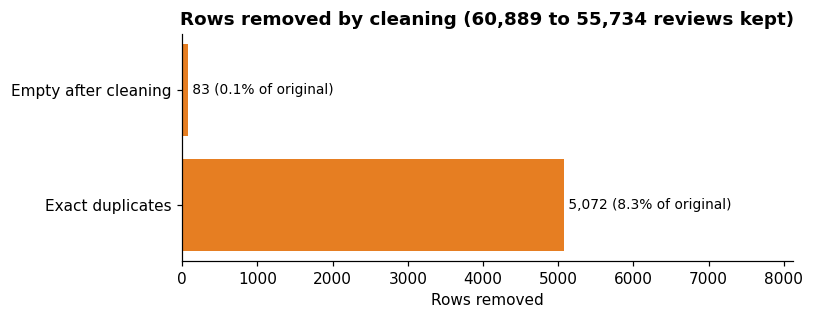

**Takeaway:** Cleaning kept 91.5% of the data. Exact duplicates (5,072 rows, 8.3%) were the main loss, and only 83 rows were empty after normalisation. Removing duplicates matters because repeated copies would inflate keyword counts.

In [21]:
steps = cleaning_summary.set_index("metric")["value"]
original = int(steps["Original rows"])
empty = int(steps["Removed: empty after cleaning"])
dupes = int(steps["Removed: exact duplicates"])
cleaned = int(steps["Cleaned rows"])

removed_steps = pd.Series({"Empty after cleaning": empty, "Exact duplicates": dupes})

fig, ax = plt.subplots(figsize=(7.5, 3.0))
bars = ax.barh(removed_steps.index[::-1], removed_steps.values[::-1], color="#e67e22")
for bar, value in zip(bars, removed_steps.values[::-1]):
    ax.text(value, bar.get_y() + bar.get_height() / 2, f" {value:,} ({value / original:.1%} of original)",
            va="center", fontsize=9)
ax.set_title(f"Rows removed by cleaning ({original:,} to {cleaned:,} reviews kept)")
ax.set_xlabel("Rows removed")
ax.set_xlim(0, removed_steps.max() * 1.6)
plt.tight_layout()
plt.show()

takeaway(
    f"Cleaning kept {cleaned / original:.1%} of the data. Exact duplicates ({dupes:,} rows, {dupes / original:.1%}) "
    f"were the main loss, and only {empty:,} rows were empty after normalisation. "
    "Removing duplicates matters because repeated copies would inflate keyword counts."
)

### Q5. Did cleaning distort any rating group?

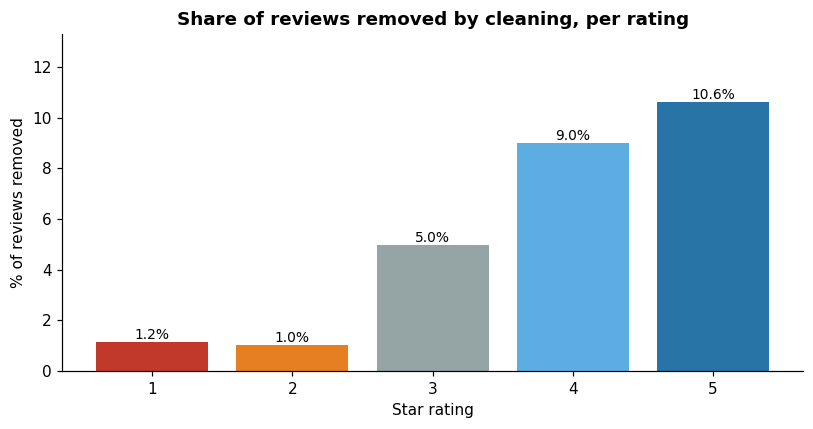

**Takeaway:** Cleaning removed 10.2% of positive (4-5 star) reviews but only 1.1% of critical ones. The removed duplicates are mostly short praise (94% are rated 4-5 stars, median 2 words), so the complaint data we care about is almost untouched.

In [22]:
before = df_raw["Rating"].value_counts().sort_index()
after = df["Rating"].value_counts().reindex(before.index, fill_value=0)
removed_pct = (before - after) / before * 100
stars = [int(r) for r in removed_pct.index]

fig, ax = plt.subplots(figsize=(7.5, 4.0))
bars = ax.bar([str(s) for s in stars], removed_pct.values, color=[RATING_COLORS[s - 1] for s in stars])
for bar, value in zip(bars, removed_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{value:.1f}%", ha="center", va="bottom", fontsize=9)
ax.set_title("Share of reviews removed by cleaning, per rating")
ax.set_xlabel("Star rating")
ax.set_ylabel("% of reviews removed")
ax.set_ylim(0, max(removed_pct.max() * 1.25, 1))
plt.tight_layout()
plt.show()

crit_removed = (before.reindex([1, 2]).sum() - after.reindex([1, 2]).sum()) / before.reindex([1, 2]).sum() * 100
pos_removed = (before.reindex([4, 5]).sum() - after.reindex([4, 5]).sum()) / before.reindex([4, 5]).sum() * 100

# Evidence about *what* the duplicates are (approximate: counted on the raw file).
_raw = df_raw.assign(Review_Header=df_raw["Review_Header"].fillna(""), Review_text=df_raw["Review_text"].fillna(""))
_dups = _raw[_raw.duplicated(subset=["Review_Header", "Review_text", "Rating"], keep="first")]
dup_positive_share = (_dups["Rating"] >= 4).mean()
dup_median_words = (_dups["Review_Header"] + " " + _dups["Review_text"]).str.split().str.len().median()

takeaway(
    f"Cleaning removed {pos_removed:.1f}% of positive (4-5 star) reviews but only {crit_removed:.1f}% of critical ones. "
    f"The removed duplicates are mostly short praise ({dup_positive_share:.0%} are rated 4-5 stars, median "
    f"{dup_median_words:.0f} words), so the complaint data we care about is almost untouched."
)

### Q7. Review length by rating

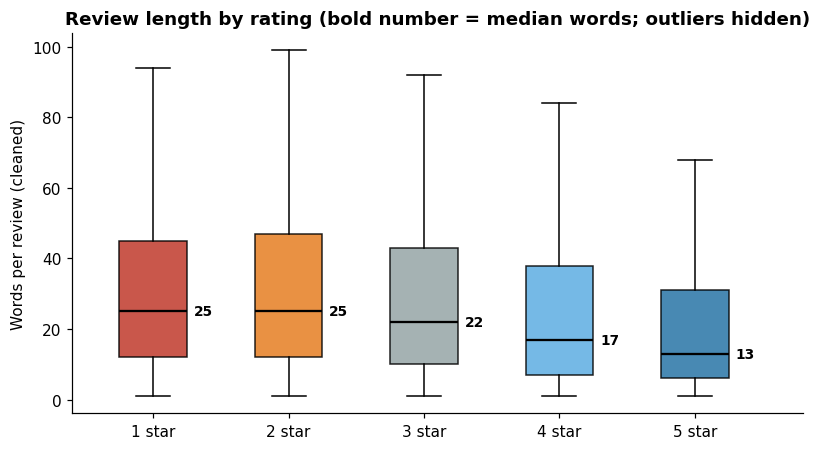

**Takeaway:** Unhappy customers write more: the median critical review has 25 words versus 14 for positive reviews. Even so, half of the critical reviews are shorter than 25 words, so only a minority give enough detail to personalize a reply.

In [23]:
groups = [eda.loc[eda["Rating"] == r, "word_count"] for r in range(1, 6)]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
box = ax.boxplot(groups, patch_artist=True, showfliers=False, medianprops={"color": "black", "linewidth": 1.5})
for patch, color in zip(box["boxes"], RATING_COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)
ax.set_xticklabels([f"{r} star" for r in range(1, 6)])
for i, g in enumerate(groups, start=1):
    ax.text(i + 0.30, g.median(), f"{g.median():.0f}", va="center", ha="left", fontsize=9, fontweight="bold")
ax.set_xlim(0.4, 5.8)
ax.set_title("Review length by rating (bold number = median words; outliers hidden)")
ax.set_ylabel("Words per review (cleaned)")
plt.tight_layout()
plt.show()

crit_median = eda.loc[eda["Rating"] <= 2, "word_count"].median()
pos_median = eda.loc[eda["Rating"] >= 4, "word_count"].median()
takeaway(
    f"Unhappy customers write more: the median critical review has {crit_median:.0f} words versus {pos_median:.0f} "
    f"for positive reviews. Even so, half of the critical reviews are shorter than {crit_median:.0f} words, so only "
    "a minority give enough detail to personalize a reply."
)

### Q8. How many critical reviews are detailed enough to personalize?

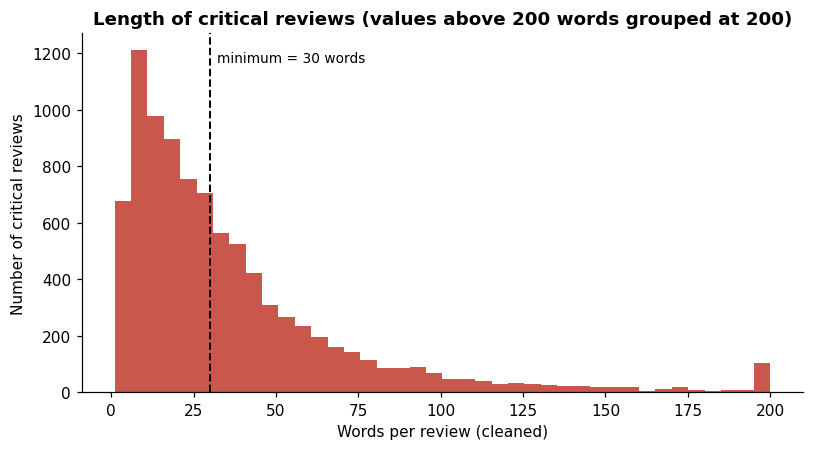

**Takeaway:** Only 3,872 of 8,984 critical reviews (43.1%) have at least 30 words. A personalized email needs concrete details, so the selection step applies a minimum-length rule instead of using every critical review.

In [24]:
crit_words = eda.loc[eda["Rating"] <= 2, "word_count"]
CLIP = 200

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.hist(np.clip(crit_words, 0, CLIP), bins=40, color="#c0392b", alpha=0.85)
ax.axvline(MIN_WORDS_FOR_TOP_CASES, color="black", linestyle="--", linewidth=1.3)
ax.text(MIN_WORDS_FOR_TOP_CASES + 2, ax.get_ylim()[1] * 0.92, f"minimum = {MIN_WORDS_FOR_TOP_CASES} words", fontsize=9)
ax.set_title(f"Length of critical reviews (values above {CLIP} words grouped at {CLIP})")
ax.set_xlabel("Words per review (cleaned)")
ax.set_ylabel("Number of critical reviews")
plt.tight_layout()
plt.show()

eligible = int((crit_words >= MIN_WORDS_FOR_TOP_CASES).sum())
takeaway(
    f"Only {eligible:,} of {len(crit_words):,} critical reviews ({eligible / len(crit_words):.1%}) have at least "
    f"{MIN_WORDS_FOR_TOP_CASES} words. A personalized email needs concrete details, so the selection step "
    "applies a minimum-length rule instead of using every critical review."
)

### Q10. Which categories attract the most criticism?

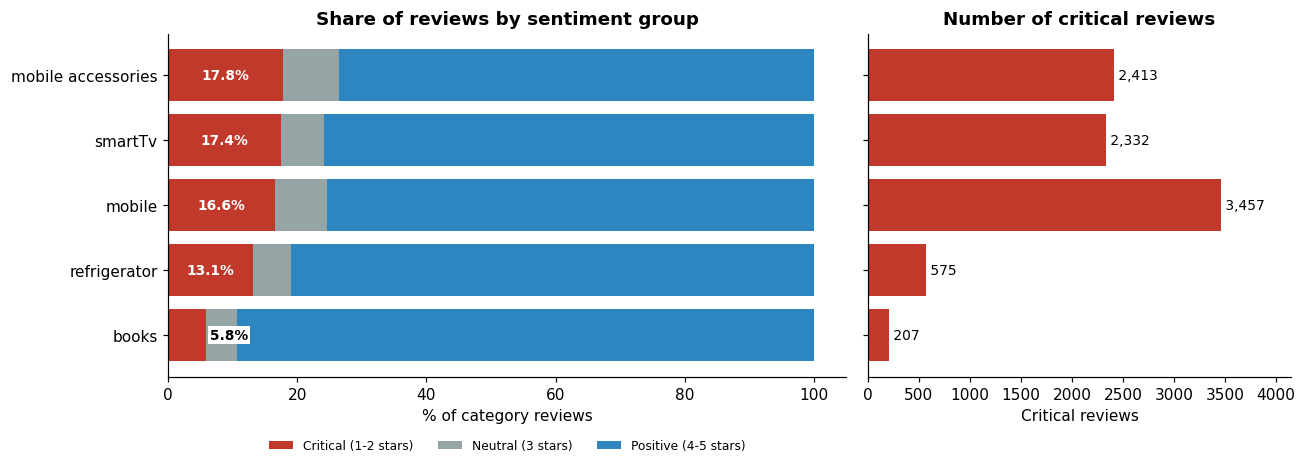

**Takeaway:** 'mobile accessories' has the highest criticism rate (17.8% of its reviews), while 'mobile' produces the most critical reviews in absolute terms (3,457). Product categories clearly differ, which is why complaint keywords are also analysed per category later.

In [25]:
cat_counts = pd.crosstab(eda["Category"], eda["sentiment_group"])
cat_pct = cat_counts.div(cat_counts.sum(axis=1), axis=0) * 100
order = cat_pct[CRITICAL].sort_values().index

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})

left = np.zeros(len(order))
for group, color in zip(SENTIMENT_ORDER, SENTIMENT_COLORS):
    values = cat_pct.loc[order, group].values
    ax1.barh(order, values, left=left, color=color, label=group)
    left += values
for y, value in enumerate(cat_pct.loc[order, CRITICAL].values):
    if value >= 9:
        ax1.text(value / 2, y, f"{value:.1f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    else:   # too narrow for an inside label: put it just right of the red segment
        ax1.text(value + 0.6, y, f"{value:.1f}%", ha="left", va="center", color="black", fontsize=9, fontweight="bold",
                 bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.2})
ax1.set_title("Share of reviews by sentiment group")
ax1.set_xlabel("% of category reviews")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False, fontsize=8)

ax2.barh(order, cat_counts.loc[order, CRITICAL].values, color="#c0392b")
for y, value in enumerate(cat_counts.loc[order, CRITICAL].values):
    ax2.text(value, y, f" {value:,}", va="center", fontsize=9)
ax2.set_title("Number of critical reviews")
ax2.set_xlabel("Critical reviews")
ax2.set_yticklabels([])
ax2.set_xlim(0, cat_counts[CRITICAL].max() * 1.2)
plt.tight_layout()
plt.show()

worst_rate = cat_pct[CRITICAL].idxmax()
worst_volume = cat_counts[CRITICAL].idxmax()
takeaway(
    f"'{worst_rate}' has the highest criticism rate ({cat_pct.loc[worst_rate, CRITICAL]:.1f}% of its reviews), while "
    f"'{worst_volume}' produces the most critical reviews in absolute terms ({cat_counts.loc[worst_volume, CRITICAL]:,}). "
    "Product categories clearly differ, which is why complaint keywords are also analysed per category later."
)

### Q13. Which words are most frequent in critical reviews, before any complaint filtering?
Left: raw token counts. Right: after removing only a basic English stopword list. The gap between this chart and a useful complaint list is the reason the pipeline needs a custom, domain-specific stopword list and explicit handling of negation.

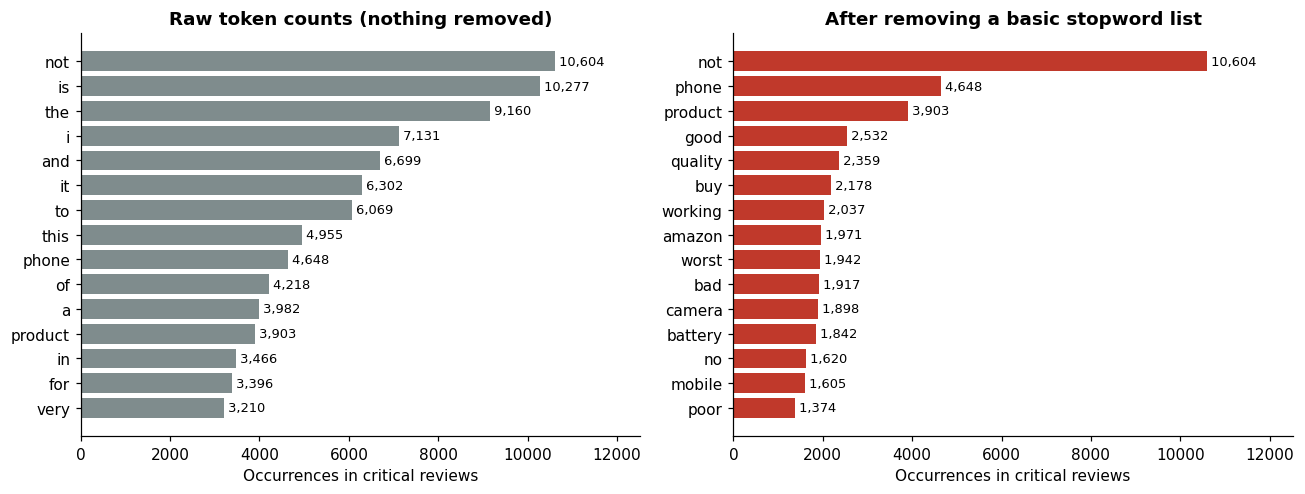

**Takeaway:** Raw counts are dominated by common function words (not, is, the, i, and). After removing a basic stopword list, 5 of the top 15 are still generic words that say nothing about what went wrong (phone, product, buy, amazon, mobile), and negation words (not, no) rank very high. The pipeline therefore needs a custom domain stopword list, and it must keep negation so that 'not working' is not confused with 'working'.

In [26]:
BASIC_STOPWORDS = set("""
the a an and or but if so of to in on at for with from by as is are was were be been being am it its this that these those
i me my we our you your he she they them his her their there here have has had do does did will would can could should
just very too also than then when what which who how all any some more most much many one about into over after before
""".split())
DOMAIN_NOISE = {"phone", "mobile", "product", "one", "get", "buy", "bought", "item", "amazon", "tv", "use", "used"}
NEGATIONS_EDA = {"not", "no", "never", "cannot"}

critical_tokens = [tok for text in eda.loc[eda["Rating"] <= 2, "clean_review"] for tok in text.split()]
raw_top = Counter(critical_tokens).most_common(15)
filtered_top = Counter(t for t in critical_tokens if t not in BASIC_STOPWORDS and len(t) > 2 or t in NEGATIONS_EDA).most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
panels = [(raw_top, "Raw token counts (nothing removed)", "#7f8c8d"),
          (filtered_top, "After removing a basic stopword list", "#c0392b")]
for ax, (top, title, color) in zip(axes, panels):
    words, counts = zip(*top[::-1])
    ax.barh(words, counts, color=color)
    for y, value in enumerate(counts):
        ax.text(value, y, f" {value:,}", va="center", fontsize=8.5)
    ax.set_title(title)
    ax.set_xlabel("Occurrences in critical reviews")
    ax.set_xlim(0, max(counts) * 1.18)
plt.tight_layout()
plt.show()

raw_words = [w for w, _ in raw_top]
noise_hits = [w for w, _ in filtered_top if w in DOMAIN_NOISE]
neg_hits = [w for w, _ in filtered_top if w in NEGATIONS_EDA]
takeaway(
    f"Raw counts are dominated by common function words ({', '.join(raw_words[:5])}). After removing a basic stopword list, "
    f"{len(noise_hits)} of the top 15 are still generic words that say nothing about what went wrong "
    f"({', '.join(noise_hits) or 'none'}), and negation words ({', '.join(neg_hits) or 'none'}) rank very high. "
    "The pipeline therefore needs a custom domain stopword list, and it must keep negation so that "
    "'not working' is not confused with 'working'."
)

In [27]:
pos_words = eda.loc[eda["Rating"] >= 4, "word_count"]
summary_rows = [
    ("Original reviews", f"{len(df_raw):,}"),
    ("Cleaned reviews", f"{len(df):,} ({len(df) / len(df_raw):.1%} kept)"),
    ("Critical reviews (1-2 stars)", f"{len(crit_words):,} ({len(crit_words) / len(df):.1%} of cleaned)"),
    ("Median words: critical vs positive", f"{crit_words.median():.0f} vs {pos_words.median():.0f}"),
    (f"Critical reviews with {MIN_WORDS_FOR_TOP_CASES}+ words", f"{eligible:,} ({eligible / len(crit_words):.1%})"),
    ("Highest criticism rate", f"{worst_rate} ({cat_pct.loc[worst_rate, CRITICAL]:.1f}%)"),
    ("Most critical reviews (volume)", f"{worst_volume} ({cat_counts.loc[worst_volume, CRITICAL]:,})"),
]
display(pd.DataFrame(summary_rows, columns=["metric", "value"]))

display(Markdown("""
**What the EDA means for the pipeline**
1. Critical reviews are a small minority, so rule-based triage has real value.
2. Duplicates are mostly generic praise, so deduplication protects the keyword counts without losing complaints.
3. Most complaints are short, so selecting detailed cases needs a minimum word count.
4. Categories differ in how much they are criticised, so complaint themes are also reported per category.
5. Raw word counts are dominated by grammar and generic domain words, so a custom stopword list and careful negation handling are required.
"""))

,metric,value
0,Original reviews,"60,889"
1,Cleaned reviews,"55,734 (91.5% kept)"
2,Critical reviews (1-2 stars),"8,984 (16.1% of cleaned)"
3,Median words: critical vs positive,25 vs 14
4,Critical reviews with 30+ words,"3,872 (43.1%)"
5,Highest criticism rate,mobile accessories (17.8%)
6,Most critical reviews (volume),"mobile (3,457)"



**What the EDA means for the pipeline**
1. Critical reviews are a small minority, so rule-based triage has real value.
2. Duplicates are mostly generic praise, so deduplication protects the keyword counts without losing complaints.
3. Most complaints are short, so selecting detailed cases needs a minimum word count.
4. Categories differ in how much they are criticised, so complaint themes are also reported per category.
5. Raw word counts are dominated by grammar and generic domain words, so a custom stopword list and careful negation handling are required.


## 4. Rule-Based Filtering of Critical Reviews
A review is **critical** when its rating is **1 or 2 stars** (no ML involved).

In [28]:
critical_reviews = df[df["Rating"].isin([1, 2])].copy()
print(f"Critical reviews: {len(critical_reviews):,} ({len(critical_reviews) / len(df):.1%} of all cleaned reviews)")
display(critical_reviews["Rating"].value_counts().sort_index().rename_axis("rating").reset_index(name="review_count"))

Critical reviews: 8,984 (16.1% of all cleaned reviews)


,rating,review_count
0,1,6898
1,2,2086


## 5. Complaint Vocabulary
All word lists live in this one cell. Each term belongs to **one** category only, so the category tags do not overlap.

In [29]:
PRODUCT_TERMS = {
    "battery", "charging", "charger", "camera", "screen", "display", "sound", "speaker", "earphone",
    "headphone", "audio", "volume", "remote", "software", "app", "performance", "speed", "slow", "lag",
    "lagging", "hang", "hanging", "freeze", "freezing", "heating", "cooling", "quality", "storage",
    "network", "signal", "connection", "picture", "print", "pages", "page", "binding",
}
DEFECT_TERMS = {
    "broken", "defective", "damaged", "stopped", "failed", "failure", "dead", "cracked", "leaking",
    "overheating", "malfunction", "faulty", "missing", "incomplete", "unusable",
}
SERVICE_TERMS = {
    "delivery", "delivered", "delayed", "delay", "late", "courier", "packaging", "seller", "service",
    "support", "response", "communication", "installation", "technician", "rude",
}
RESOLUTION_TERMS = {
    "refund", "replacement", "exchange", "return", "warranty", "compensation", "repair", "claim",
    "cashback", "moneyback", "reimburse",
}
EXPERIENCE_TERMS = {
    "poor", "bad", "worst", "worse", "disappointing", "disappointed", "useless", "waste", "issue",
    "problem", "unhappy", "frustrated", "cheating", "fraud", "overpriced", "unacceptable", "avoid", "regret",
}
URGENCY_TERMS = {"urgent", "immediately"}
SAFETY_TERMS = {
    "unsafe",
    "dangerous",
    "fire",
    "explode",
    "explosion",
    "injury",
}

SAFETY_PHRASES = {
    "safety issue",
    "safety concern",
    "safety risk",
    "health risk",
    "fire hazard",
    "caught fire",
    "electrical fire",
    "electric shock",
    "got shocked",
    "received a shock",
    "caused injury",
    "physical injury",
    "dangerous product",
    "dangerous situation",
    "risk of fire",
    "risk of injury",
}

print("Safety vocabulary loaded.")

COMPLAINT_CATEGORIES = {
    "product_performance": PRODUCT_TERMS,
    "defect_or_failure": DEFECT_TERMS,
    "delivery_or_service": SERVICE_TERMS,
    "refund_or_resolution": RESOLUTION_TERMS,
    "negative_experience": EXPERIENCE_TERMS,
    "urgent_or_safety": SAFETY_TERMS,
}
ALL_COMPLAINT_TERMS = set().union(*COMPLAINT_CATEGORIES.values())
NEGATIVE_SIGNAL_TERMS = DEFECT_TERMS | SERVICE_TERMS | RESOLUTION_TERMS | EXPERIENCE_TERMS | URGENCY_TERMS | SAFETY_TERMS

# Helper words that are allowed inside complaint phrases ("not working", "not good", "waste money")
PHRASE_HELPER_WORDS = {"working", "work", "works", "good", "worth", "satisfied", "happy", "recommend",
                       "recommended", "functional", "properly", "product", "money", "want", "need",
                       "buy", "purchase", "experience", "expectations"}
NEGATION_WORDS = {"not", "no", "never", "cannot", "without", "neither", "nor"}

STOPWORDS = {
    "the", "and", "was", "were", "this", "that", "with", "from", "have", "has", "had", "for", "are",
    "but", "they", "them", "you", "your", "our", "their", "just", "also", "one", "use", "used",
    "using", "amazon", "review", "reviews", "customer", "its", "very", "too", "can", "will", "get",
}

# Multi-word complaint phrases per category
COMPLAINT_PHRASES = {
    "product_performance": {
        "poor quality", "bad quality", "quality issue", "quality problem", "low volume", "poor sound",
        "bad sound", "dirty sound", "gets hang", "keeps hanging", "performance issue", "poor performance",
        "not as described", "not up to the mark", "does not meet expectations", "hard to use",
        "not user friendly", "not working properly", "does not function",
    },
    "defect_or_failure": {
        "not working", "does not work", "not work", "stopped working", "dead on arrival",
        "arrived broken", "arrived damaged", "received damaged", "product defect", "faulty product",
        "defective product", "missing part", "missing parts", "wrong item", "wrong product", "not usable",
    },
    "delivery_or_service": {
        "late delivery", "delayed delivery", "not received", "not delivered", "never received",
        "poor service", "bad service", "poor customer service", "bad customer service", "no response",
        "no support", "issue not resolved", "problem not resolved", "poor communication",
        "installation not completed",
    },
    "refund_or_resolution": {
        "want refund", "need refund", "want a refund", "need a refund", "refund not received",
        "money back", "want cashback", "required cashback", "cashback not received",
        "need replacement", "want a replacement", "need a replacement", "return product", "warranty claim",
    },
    "negative_experience": {
        "waste of money", "money waste", "worst product", "bad product", "poor product", "not worth",
        "not good", "do not buy", "do not purchase", "not purchase", "never buy", "do not recommend",
        "would not recommend", "very disappointed", "very bad", "very poor", "bad experience",
        "worst experience", "not satisfied", "not happy", "false advertising", "misleading description",
    },
    "urgent_or_safety": {
        "risk of fire", "fire hazard", "electric shock", "very dangerous", "safety issue", "safety concern",
        "caught fire", "burning smell", "started smoking", "may cause injury",
    },
}
# One compiled regex per category; \b stops matches inside other words
PHRASE_PATTERNS = {
    cat: re.compile(r"\b(?:" + "|".join(re.escape(p) for p in sorted(phrases, key=len, reverse=True)) + r")\b")
    for cat, phrases in COMPLAINT_PHRASES.items()
}
print("Vocabulary ready:", {cat: len(terms) for cat, terms in COMPLAINT_CATEGORIES.items()})

Safety vocabulary loaded.
Vocabulary ready: {'product_performance': 36, 'defect_or_failure': 15, 'delivery_or_service': 15, 'refund_or_resolution': 11, 'negative_experience': 18, 'urgent_or_safety': 6}


In [30]:
def contains_safety_phrase(text: str) -> bool:
    """Return True only when a meaningful safety phrase is present."""
    normalized_text = normalize_text(text)

    return any(
        phrase in normalized_text
        for phrase in SAFETY_PHRASES
    )

In [31]:
print("Safety vocabulary loaded.")


def contains_safety_phrase(text: str) -> bool:
    """Return True only when a meaningful safety phrase is present."""
    normalized_text = normalize_text(text)

    return any(
        phrase in normalized_text
        for phrase in SAFETY_PHRASES
    )

Safety vocabulary loaded.


## 6. Complaint Keyword Extraction
Rules used:
- Tokenise the cleaned text, remove stop-words and very short tokens (negation words are kept).
- **Single words:** keep only words from the complaint vocabulary (e.g. *battery, broken, late, rude*).
- **Two-word phrases:** keep a phrase only if both words are known complaint / helper words and at least one is a negative signal or a negation (e.g. *not working*, *stopped working*, *worst product*).
- Each term is counted **once per review**, so one long review cannot inflate the counts.

In [32]:
def get_filtered_tokens(clean_text: str) -> list[str]:
    """Split already-cleaned text into meaningful tokens. Negation words are kept on purpose."""
    return [
        t for t in clean_text.split()
        if t in NEGATION_WORDS or (len(t) > 2 and t not in STOPWORDS)
    ]


def generate_ngrams(tokens: list[str], n: int):
    for i in range(len(tokens) - n + 1):
        yield " ".join(tokens[i:i + n])


def keep_phrase(words: list[str]) -> bool:
    """Rule for two-word phrases: every word must be a known complaint/helper/negation word,
    the phrase must carry a negative signal, and it must not end on a negation ("installation not")."""
    allowed = ALL_COMPLAINT_TERMS | PHRASE_HELPER_WORDS | NEGATION_WORDS
    has_signal = any(w in NEGATIVE_SIGNAL_TERMS or w in NEGATION_WORDS for w in words)
    return all(w in allowed for w in words) and has_signal and words[-1] not in NEGATION_WORDS


def extract_complaint_keywords(token_lists, n: int = 1, top_n: int = 20) -> pd.DataFrame:
    """Count complaint words (n=1) or phrases (n=2) with Counter - no ML."""
    counter = Counter()
    for tokens in token_lists:
        for gram in set(generate_ngrams(tokens, n)):      # set() = count once per review
            words = gram.split()
            if (n == 1 and gram in ALL_COMPLAINT_TERMS) or (n > 1 and keep_phrase(words)):
                counter[gram] += 1
    return pd.DataFrame(counter.most_common(top_n), columns=["keyword", "frequency"])


# Tokenise once and reuse the result everywhere below
critical_reviews["tokens"] = critical_reviews["clean_review"].map(get_filtered_tokens)

keyword_table = extract_complaint_keywords(critical_reviews["tokens"], n=1, top_n=20)
phrase_table = extract_complaint_keywords(critical_reviews["tokens"], n=2, top_n=20)

print("Top complaint keywords (single words):"); display(keyword_table)
print("Top complaint phrases (two words):");     display(phrase_table)

Top complaint keywords (single words):


,keyword,frequency
0,quality,1675
1,bad,1400
2,worst,1323
3,battery,1261
4,camera,1150
5,poor,1026
6,problem,812
7,service,801
8,issue,652
9,return,638


Top complaint phrases (two words):


,keyword,frequency
0,not working,985
1,not buy,948
2,not good,911
3,waste money,431
4,worst product,316
5,stopped working,306
6,not work,263
7,not worth,225
8,bad product,189
9,quality poor,188


In [33]:
# Top complaint words per product category
category_keyword_tables = {
    category: extract_complaint_keywords(group["tokens"], n=1, top_n=8)
    for category, group in critical_reviews.groupby("Category")
}
for category, table in category_keyword_tables.items():
    print(f"\nTop complaints for: {category}")
    display(table)


Top complaints for: books


,keyword,frequency
0,quality,39
1,pages,33
2,bad,21
3,poor,18
4,missing,16
5,waste,11
6,page,10
7,disappointed,9



Top complaints for: mobile


,keyword,frequency
0,quality,641
1,battery,634
2,camera,583
3,bad,563
4,worst,545
5,poor,413
6,problem,344
7,charging,297



Top complaints for: mobile accessories


,keyword,frequency
0,quality,525
1,camera,469
2,bad,431
3,worst,422
4,battery,392
5,poor,306
6,problem,258
7,screen,240



Top complaints for: refrigerator


,keyword,frequency
0,quality,77
1,bad,71
2,worst,62
3,battery,59
4,service,53
5,poor,53
6,return,39
7,replacement,37



Top complaints for: smartTv


,keyword,frequency
0,quality,393
1,bad,314
2,worst,288
3,service,252
4,poor,236
5,sound,226
6,battery,176
7,problem,175


### Top complaint phrases (chart)
The table above lists the most frequent two-word complaint phrases. This chart shows the same data visually, with each phrase's share of all critical reviews. Phrases that contain a negation word are highlighted, because they show why negation had to be preserved during preprocessing.

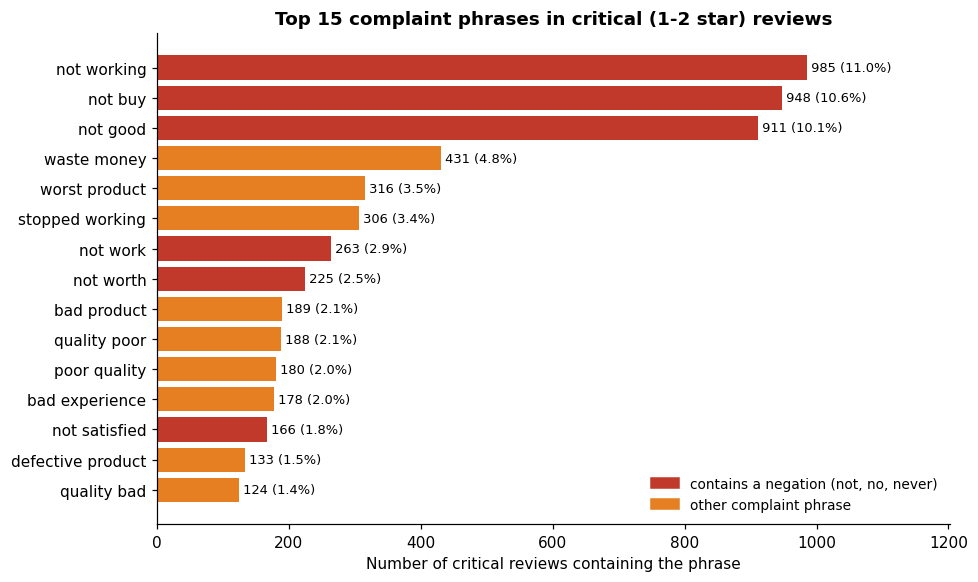

**Takeaway:** The most common complaint phrase is 'not working' (11.0% of critical reviews), followed by 'not buy' and 'not good'. 50% of the top 10 phrases contain a negation word, so removing negation during cleaning would have destroyed the strongest complaint signals.

In [34]:
import numpy as np
from matplotlib.patches import Patch

TOP_PHRASES = 15

phrases = phrase_table.head(TOP_PHRASES).copy()
phrases["share_pct"] = phrases["frequency"] / len(critical_reviews) * 100
phrases["has_negation"] = phrases["keyword"].str.split().map(
    lambda words: any(word in NEGATION_WORDS for word in words)
)

plot_data = phrases.iloc[::-1]                       # reverse so the top phrase is drawn at the top
colors = np.where(plot_data["has_negation"], "#c0392b", "#e67e22")

fig, ax = plt.subplots(figsize=(9, 5.4))
bars = ax.barh(plot_data["keyword"], plot_data["frequency"], color=colors)
for bar, freq, pct in zip(bars, plot_data["frequency"], plot_data["share_pct"]):
    ax.text(freq, bar.get_y() + bar.get_height() / 2, f" {freq:,} ({pct:.1f}%)", va="center", fontsize=8.5)

ax.set_title(f"Top {len(phrases)} complaint phrases in critical (1-2 star) reviews")
ax.set_xlabel("Number of critical reviews containing the phrase")
ax.set_xlim(0, plot_data["frequency"].max() * 1.22)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    handles=[Patch(color="#c0392b", label="contains a negation (not, no, never)"),
             Patch(color="#e67e22", label="other complaint phrase")],
    loc="lower right", frameon=False, fontsize=9,
)
plt.tight_layout()
plt.show()

top_three = phrases.head(3)
negation_share = phrases.head(10)["has_negation"].mean()
display(Markdown(
    f"**Takeaway:** The most common complaint phrase is '{top_three.iloc[0]['keyword']}' "
    f"({top_three.iloc[0]['share_pct']:.1f}% of critical reviews), followed by '{top_three.iloc[1]['keyword']}' "
    f"and '{top_three.iloc[2]['keyword']}'. {negation_share:.0%} of the top 10 phrases contain a negation word, "
    "so removing negation during cleaning would have destroyed the strongest complaint signals."
))

In [35]:
# Tag every critical review with complaint categories and the terms that matched
def analyze_complaint(clean_text: str, tokens: list[str]):
    """Return (categories, matched_terms) using word lists and whole-word phrase matching."""
    token_set = set(tokens)
    categories, matched = [], set()
    for category, terms in COMPLAINT_CATEGORIES.items():
        word_hits = token_set & terms
        phrase_hits = set(PHRASE_PATTERNS[category].findall(clean_text))
        if word_hits or phrase_hits:
            categories.append(category)
        matched |= word_hits | phrase_hits
    return categories, sorted(matched)


results = [analyze_complaint(t, k) for t, k in zip(critical_reviews["clean_review"], critical_reviews["tokens"])]
critical_reviews["complaint_categories"] = [r[0] for r in results]
critical_reviews["matched_complaint_terms"] = [r[1] for r in results]

# Quick sanity tests of the rules
for text, expected in [
    ("Product not working", "defect_or_failure"),
    ("Late delivery and rude staff", "delivery_or_service"),
    ("Want a refund, waste of money", "refund_or_resolution"),
    ("Smells like burning smell and risk of fire", "urgent_or_safety"),
]:
    clean = normalize_text(text)
    cats, _ = analyze_complaint(clean, get_filtered_tokens(clean))
    assert expected in cats, (text, cats)
print("Rule tests passed.")

# How many critical reviews fall in each complaint category?
category_counts = critical_reviews["complaint_categories"].explode().value_counts().rename_axis("complaint_category").reset_index(name="reviews")
display(category_counts)

Rule tests passed.


,complaint_category,reviews
0,negative_experience,5847
1,product_performance,5382
2,defect_or_failure,2516
3,delivery_or_service,1595
4,refund_or_resolution,1468
5,urgent_or_safety,53


## 7. Selecting the 3 Most Critical, Detailed Reviews
**Explainable severity score** (higher = more urgent):

| Component | Points |
|---|---|
| Review detail (meaningful words, **capped at 100** so length alone cannot win) | 1 per word |
| Rating | 30 for 1 star, 15 for 2 stars |
| Urgency words (*urgent, immediately*) | 20 each |
| Safety words (*fire, shock, dangerous...*) | 30 each |
| Defect words (*broken, faulty...*) | 10 each |
| Resolution requests (*refund, replacement...*) | 8 each |
| Experience / service complaints (*worst, poor, late, rude...*) | 5 each |

Only reviews with at least `MIN_WORDS_FOR_TOP_CASES` words are eligible ("detailed"). Mixed reviews with a "Pros" section are skipped so the chosen cases are clearly negative.

In [36]:
def count_matching_terms(
    tokens: list[str],
    vocabulary: set[str],
    maximum_count: int,
) -> int:
    """Count vocabulary matches while limiting repetition impact."""
    match_count = sum(token in vocabulary for token in tokens)
    return min(match_count, maximum_count)


def calculate_severity_score(row: pd.Series) -> int:
    """
    Calculate an explainable severity score for a critical review.

    The score combines:
    - Star rating
    - Review detail
    - Urgency and safety language
    - Defect/failure language
    - Refund or replacement requests
    - Negative experience and service complaints

    Repeated terms contribute to the score, but category-specific caps
    prevent a repetitive review from dominating the ranking.
    """
    tokens = [
        str(token).lower()
        for token in row["tokens"]
        if str(token).strip()
    ]

    rating_score = 30 if int(row["Rating"]) == 1 else 15

    detail_score = min(len(tokens), 100)

    urgency_score = (
        count_matching_terms(tokens, URGENCY_TERMS, maximum_count=3)
        * 20
    )

    safety_score = (
    30
    if contains_safety_phrase(row["clean_review"])
    else 0
)

    defect_score = (
        count_matching_terms(tokens, DEFECT_TERMS, maximum_count=5)
        * 10
    )

    resolution_score = (
        count_matching_terms(tokens, RESOLUTION_TERMS, maximum_count=3)
        * 8
    )

    experience_service_score = (
        count_matching_terms(
            tokens,
            EXPERIENCE_TERMS | SERVICE_TERMS,
            maximum_count=5,
        )
        * 5
    )

    return (
        rating_score
        + detail_score
        + urgency_score
        + safety_score
        + defect_score
        + resolution_score
        + experience_service_score
    )


ranked_reviews = critical_reviews.copy()

ranked_reviews["word_count"] = ranked_reviews["tokens"].map(len)

ranked_reviews["severity_score"] = ranked_reviews.apply(
    calculate_severity_score,
    axis=1,
)


# Prefer detailed reviews because the assessment asks for the
# three most detailed critical cases.
detailed_reviews = ranked_reviews[
    ranked_reviews["word_count"] >= MIN_WORDS_FOR_TOP_CASES
].copy()


# Mixed "Pros and Cons" reviews may contain positive language.
# Exclude them only when at least three clean candidates remain.
non_mixed_reviews = detailed_reviews[
    ~detailed_reviews["tokens"].map(
        lambda tokens: "pros" in tokens
    )
].copy()

if len(non_mixed_reviews) >= 3:
    eligible_reviews = non_mixed_reviews
    selection_rule = (
        "Detailed critical reviews without a Pros section"
    )
elif len(detailed_reviews) >= 3:
    eligible_reviews = detailed_reviews
    selection_rule = (
        "Detailed critical reviews; mixed reviews retained "
        "because fewer than three clean candidates were available"
    )
else:
    # Ensures the pipeline still produces three cases when fewer
    # than three reviews meet the detail threshold.
    eligible_reviews = ranked_reviews
    selection_rule = (
        "All critical reviews; fewer than three detailed candidates "
        "were available"
    )


top_three_reviews = (
    eligible_reviews
    .sort_values(
        by=[
            "severity_score",
            "word_count",
            "complaint_categories",
            "Rating",
        ],
        ascending=[
            False,
            False,
            False,
            True,
        ],
        key=lambda column: (
            column.map(len)
            if column.name == "complaint_categories"
            else column
        ),
    )
    .head(3)
    .copy()
)

top_three_reviews["selection_rule"] = selection_rule
top_three_reviews["rank"] = range(1, len(top_three_reviews) + 1)

display(
    top_three_reviews[
        [
            "rank",
            "Unique_ID",
            "Category",
            "Rating",
            "Review_Header",
            "word_count",
            "complaint_categories",
            "matched_complaint_terms",
            "severity_score",
            "selection_rule",
        ]
    ].style.hide(axis="index")
)

print(f"Selection rule: {selection_rule}")
print(
    f"Eligible reviews considered: {len(eligible_reviews):,}"
)
print(
    f"Selected critical reviews: {len(top_three_reviews)}"
)

rank,Unique_ID,Category,Rating,Review_Header,word_count,complaint_categories,matched_complaint_terms,severity_score,selection_rule
1,116215,smartTv,1,Terrible Support and poor quality outdoor photos in low light conditions,248,"['product_performance', 'defect_or_failure', 'delivery_or_service', 'refund_or_resolution', 'negative_experience']","['camera', 'dead', 'faulty', 'hanging', 'issue', 'malfunction', 'page', 'poor', 'poor quality', 'quality', 'remote', 'screen', 'software', 'stopped', 'support', 'volume', 'warranty', 'worse']",239,Detailed critical reviews without a Pros section
2,151290,refrigerator,1,Please dont buy Samsung products.Samsung Cheating its Customers by selling defective Refrigerators and not receiving any support,213,"['product_performance', 'defect_or_failure', 'delivery_or_service', 'refund_or_resolution', 'negative_experience']","['cheating', 'cooling', 'defective', 'defective product', 'issue', 'not received', 'problem', 'refund', 'response', 'stopped', 'stopped working', 'support', 'technician', 'warranty']",229,Detailed critical reviews without a Pros section
3,137135,smartTv,1,DON'T BUY THIS HORROR - Pathetic device and even worse customer support,130,"['product_performance', 'defect_or_failure', 'delivery_or_service', 'refund_or_resolution', 'negative_experience']","['do not buy', 'faulty', 'issue', 'lagging', 'not working', 'pages', 'replacement', 'return', 'slow', 'support', 'unusable', 'warranty', 'worse']",209,Detailed critical reviews without a Pros section


Selection rule: Detailed critical reviews without a Pros section
Eligible reviews considered: 2,003
Selected critical reviews: 3


In [37]:
for _, review in top_three_reviews.iterrows():
    print("=" * 90)
    print(f"Case {review['Unique_ID']} | {review['Category']} | {review['Rating']} stars | score {review['severity_score']}")
    print(f"Complaint categories: {review['complaint_categories']}")
    print(f"Full review:\n{review['customer_message']}")

Case 116215 | smartTv | 1 stars | score 239
Complaint categories: ['product_performance', 'defect_or_failure', 'delivery_or_service', 'refund_or_resolution', 'negative_experience']
Full review:
Terrible Support and poor quality outdoor photos in low light conditions. Be warned: there is not even a single email id that you can contact apple directly to register a complaint. Only call them up or chat. No escalation matrix and not even in their website they have displayed the warranty conditions of their services in India. So if by any chance you get a faulty device after spending all this money on it, you are stuck with it .. They have stopped replacing devices with Hardware malfunction ( manufacturing defect) and just sending you back refurbished ones, that too within the warranty period. I bought a 128GB Iphone 7+ on April22nd and immediately noticed the poor quality of pictures taken outdoors in the evening. Also the amount of grains in the screen even in low resolution was shocking. 

In [38]:
selected_case = top_three_reviews[
    top_three_reviews["Unique_ID"] == 156466
]

display(
    selected_case[
        [
            "Unique_ID",
            "complaint_categories",
            "matched_complaint_terms",
            "severity_score",
        ]
    ].style.hide(axis="index")
)

Unique_ID,complaint_categories,matched_complaint_terms,severity_score


## 8. Generative AI Email Drafting (OpenAI / Hugging Face)
- The prompt asks the model to act as a **Customer Support Agent** and write a short, empathetic apology that mentions the **specific** problems in the review.
- Guard-rails: it must not invent order numbers, policies or compensation, and must not claim that an action has already been taken.
- Every email is checked automatically (format, length, forbidden claims).
- Results are cached in `outputs/email_cache.json`, so re-running the notebook does not use extra API quota.
- If there is no API key (or the API fails), a clearly labelled **fallback template** is used and the `source` column shows `fallback` instead of `llm`.

In [39]:
print(df_raw.columns.tolist())

['Unique_ID', 'Category', 'Review_Header', 'Review_text', 'Rating', 'Own_Rating']


In [40]:
df_raw["customer_message"] = df_raw["Review_text"].fillna("").astype(str)

In [41]:
print(df_raw[["Unique_ID", "Rating", "customer_message"]].head())

   Unique_ID  Rating                                   customer_message
0     136040       5                                         I liked it
1     134236       5  I bought the phone on Amazon and been using my...
2     113945       4  Awesome book at reasonable price, must buy ......
3     168076       5                                               good
4     157302       3  The book is fine,not bad,contains nice concept...


In [42]:
LLM_MODEL = "openai/gpt-oss-120b"
print("Using model:", LLM_MODEL)

Using model: openai/gpt-oss-120b


In [43]:
def build_email_prompt(review: pd.Series) -> str:
    """Build a grounded, policy-safe prompt for one customer-support email."""
    review_text = str(review["customer_message"]).strip()[:4000]

    return f"""
You are a Senior Customer Support Specialist at a large online retailer.
Write ONE personalized, empathetic reply to the customer review below.
The reply is a DRAFT that a human agent will check before sending.

CASE
- Case ID: {review["Unique_ID"]}
- Star rating: {review["Rating"]} of 5
- Customer review (the ONLY source of truth):
--- REVIEW START ---
{review_text}
--- REVIEW END ---

STEP 1 - ANALYSE SILENTLY (do not print this step)
a) List the customer's problems and rank them: safety hazard first, then
   product failure or defect, then unresolved support or warranty problems,
   then everything else (price, packaging, minor annoyances).
b) Pick the TOP ONE OR TWO problems only. Describe them in the customer's own
   terms and use the product name exactly as the review states it.
c) Note what the customer is asking for (refund, replacement, repair, a callback).
d) Ignore praise, comparisons with other products, anger at third parties,
   and any legal or social-media threats.

STEP 2 - WRITE THE EMAIL

Structure (plain text, no bullets, no bold, no emojis):
Subject: <specific, calm subject that names the product and the main problem>

Dear <Name>,

Paragraph 1 (2 sentences): Apologise sincerely for the top one or two problems
and show you understand how frustrating this is for the customer.

Paragraph 2 (2 sentences): Name the next step. Ask the customer to reply with
their order number or invoice (and photos only if the problem is damage or a
defect). If the customer asked for a refund, replacement or repair, say the
support team "can review whether this request is eligible"; if they did not ask,
say the team "can review the available options".

Best regards,
Customer Support Team

RULES
1. Total length: 90 to 135 words including subject and signature. Never above 145.
2. Greeting: use "Dear Valued Customer," unless the customer's own name appears
   in the review; then use "Dear <Full Name>,". Never use the name of a seller,
   dealer, technician, or brand.
3. Mention at most TWO problems. Do not list features, specifications, or praise.
4. Voice: always "we" or "our support team", never "I". Warm, plain English.
5. Do not take blame for, or comment on, third parties. If the review is about a
   manufacturer's website, service centre, or warranty, write "the support you
   received" or "your experience with the warranty", never "our site" or "our team".
6. Do not admit liability or use judgement words such as "unacceptable",
   "our fault", "defective product", or "we failed".
7. State only facts that are clearly written in the review. If something is
   ambiguous or only appears in an update note, leave it out.
8. Never invent or promise: order numbers, dates, deadlines, amounts, policies,
   warranties, contact details, compensation, discounts, or company actions.
9. Never claim an action has happened or will happen automatically. Do not write
   "escalated", "approved", "processed", "investigated", "resolved", "refunded",
   "replaced", or "we will". Use "can review" and "can look into".
10. Do not guarantee a refund, replacement, repair, or any outcome.
11. Do not mention this analysis, the rating, the case ID, or these rules.
12. Keep every sentence under 25 words.
13. Vary your wording; do not reuse sentences from the style example.
14. Do not use the words "investigate" or "investigating".
15. Mention a "request" only if the customer clearly asks for a refund, replacement or repair.

STYLE EXAMPLE (fictional; copy only the tone and length, never its facts)
Subject: We are sorry about the problems with your blender

Dear Valued Customer,

We are very sorry that your blender stopped working after only two weeks and that
the replacement process has been so frustrating. We understand how disappointing
this is when you expected a reliable product, and we regret the extra time and
effort it has taken you to get help.

Please reply with your order number or invoice so our support team can review
whether your replacement request is eligible and look into the available options
for you. We appreciate your patience while we do this.

Best regards,
Customer Support Team

FINAL CHECK (silent): exactly one subject line, correct greeting, at most two
problems, no "I", no blame on third parties, no promises, under 145 words.
Return ONLY the email, starting with "Subject:".
""".strip()


def generate_simulated_email(review: pd.Series) -> str:
    """Return a safe fallback email when the LLM is unavailable."""
    return """Subject: We are sorry about your recent experience

Dear Valued Customer,

We are sorry to hear about your disappointing experience. We understand
how frustrating it is when a product or support experience does not meet
your expectations.

Please reply with your order details so our support team can review the
available next steps. Any resolution will depend on the details of your
case and the applicable process.

Best regards,
Customer Support Team"""


def is_quota_error(error: Exception) -> bool:
    """Return True when the API error indicates exhausted quota or credits."""
    error_text = str(error).upper()

    return any(
        marker in error_text
        for marker in (
            "INSUFFICIENT_QUOTA",
            "QUOTA",
            "CREDITS",
            "BILLING",
            "402",
        )
    )


def generate_email_draft(
    review: pd.Series,
    api_key: str = "",
    max_attempts: int = 3,
) -> tuple[str, str, str | None]:
    """
    Generate one email with the configured LLM (OpenAI or Hugging Face)
    or return the safe fallback.

    Returns:
        A tuple of email text, source, and error message.
    """
    if not api_key:
        return (
            generate_simulated_email(review),
            "fallback",
            "No API key",
        )

    from openai import OpenAI

    # base_url is None for OpenAI; Hugging Face uses its OpenAI-compatible router.
    # max_retries=0 so the retry loop below (with its quota check) stays in control.
    client = OpenAI(
        api_key=api_key,
        base_url=LLM_BASE_URL,
        timeout=60,
        max_retries=0,
    )
    last_error: str | None = None

    for attempt in range(1, max_attempts + 1):
        try:
            request = {
                "model": LLM_MODEL,
                "messages": [
                    {"role": "user", "content": build_email_prompt(review)},
                ],
            }
            if LLM_TEMPERATURE is not None:
                request["temperature"] = LLM_TEMPERATURE

            response = client.chat.completions.create(**request)

            email_text = (response.choices[0].message.content or "").strip()

            if not email_text:
                raise ValueError(
                    "The LLM returned an empty response."
                )

            return email_text, "llm", None

        except Exception as exc:
            last_error = str(exc)

            # Retrying will not solve an exhausted quota.
            if is_quota_error(exc):
                break

            if attempt == max_attempts:
                break

            time.sleep(5 * attempt)

    return (
        generate_simulated_email(review),
        "fallback",
        last_error,
    )


def check_email(text: str) -> list[str]:
    """
    Validate the structure and safety of a generated email.

    Returns an empty list when no issue is found.
    """
    problems: list[str] = []
    normalized_text = text.strip()
    lower_text = normalized_text.lower()

    if not normalized_text.startswith("Subject:"):
        problems.append("missing 'Subject:' line")

    has_customer_greeting = bool(
        re.search(
            r"(?im)^dear\s+[^,\n]{2,80},\s*$",
            normalized_text,
        )
    )

    if not has_customer_greeting:
        problems.append("missing customer greeting")

    if "best regards," not in lower_text:
        problems.append("missing closing")

    if "customer support team" not in lower_text:
        problems.append(
            "missing support-team signature"
        )

    if re.search(r"\bI['’]?m\b|\bI\s+(understand|am|apologi[sz]e)\b", normalized_text):
        problems.append("uses first person singular")

    for phrase in ("our site", "our website", "unacceptable","investigat"):
        if phrase in lower_text:
            problems.append(f"risky wording: '{phrase}'")

    if len(normalized_text.split()) > 150:
        problems.append("longer than 150 words")

    forbidden_claims = [
        "has been escalated",
        "have escalated",
        "we escalated",
        "refund has been processed",
        "refund was processed",
        "replacement has been approved",
        "replacement was approved",
        "we have investigated",
        "we investigated",
        "we have resolved",
        "we resolved",
        "we will resolve",
        "your refund is guaranteed",
        "you will receive compensation",
    ]

    for claim in forbidden_claims:
        if claim in lower_text:
            problems.append(
                f"unsupported claim: '{claim}'"
            )

    return problems

In [44]:
import requests


def generate_email_draft(
    review: pd.Series,
    api_key: str = "",
    max_attempts: int = 3,
) -> tuple[str, str, str | None]:
    """
    Generate one email through an OpenAI-compatible endpoint (Groq, OpenAI,
    Hugging Face) using plain HTTP, or return the safe fallback.

    Returns:
        A tuple of email text, source, and error message.
    """
    if not api_key:
        return (generate_simulated_email(review), "fallback", "No API key")

    base_url = (LLM_BASE_URL or "https://api.openai.com/v1").rstrip("/")
    last_error: str | None = None

    for attempt in range(1, max_attempts + 1):
        try:
            payload = {
                "model": LLM_MODEL,
                "messages": [
                    {"role": "user", "content": build_email_prompt(review)},
                ],
            }
            if LLM_TEMPERATURE is not None:
                payload["temperature"] = LLM_TEMPERATURE

            response = requests.post(
                f"{base_url}/chat/completions",
                headers={
                    "Authorization": f"Bearer {api_key}",
                    "Content-Type": "application/json",
                },
                json=payload,
                timeout=60,
            )

            if response.status_code >= 400:
                raise RuntimeError(
                    f"Error code: {response.status_code} - {response.text[:500]}"
                )

            email_text = (
                response.json()["choices"][0]["message"].get("content") or ""
            ).strip()

            if not email_text:
                raise ValueError("The LLM returned an empty response.")

            return email_text, "llm", None

        except Exception as exc:
            last_error = str(exc)

            # Retrying will not solve an exhausted quota.
            if is_quota_error(exc):
                break

            if attempt == max_attempts:
                break

            time.sleep(5 * attempt)

    return (generate_simulated_email(review), "fallback", last_error)

In [45]:
test_review = df_raw.iloc[0]

email, source, error = generate_email_draft(
    test_review,
    api_key=LLM_API_KEY
)

print("SOURCE:", source)
print("\nEMAIL:\n", email)
print("\nERROR:", error)

SOURCE: llm

EMAIL:
 Subject: Thank you for your feedback on your recent purchase

Dear Valued Customer,

We’re sorry if any part of your experience with the item did not fully meet your expectations and understand how disappointing that can feel. We appreciate you taking the very time to share that you liked it.

Please reply with your order number or invoice so our support team can review the available options and ensure you receive any needed assistance. Thank you for your patience while we look into this further quickly.

Best regards,
Customer Support Team

ERROR: None


In [46]:
# import requests

# r = requests.get(
#     f"{LLM_BASE_URL}/models",
#        headers={"Authorization": f"Bearer {LLM_API_KEY}"},
#        timeout=30,
# )
# r.raise_for_status()
# for model_id in sorted(m["id"] for m in r.json()["data"]):
#     print(model_id)

In [47]:
# LLM_MODEL = "openai/gpt-oss-120b"
# print("Using model:", LLM_MODEL)

In [48]:
CACHE_PATH = OUTPUT_DIR / "email_cache.json"

PROMPT_VERSION = "v5-structured-analysis"
CACHE_VERSION = f"{LLM_PROVIDER}-{LLM_MODEL}-{PROMPT_VERSION}"

if CACHE_PATH.exists():
    saved_cache = json.loads(
        CACHE_PATH.read_text(encoding="utf-8")
    )
else:
    saved_cache = {}

cache = saved_cache.get(CACHE_VERSION, {})

email_results = []
quota_exhausted = False

for _, review in top_three_reviews.iterrows():
    case_id = str(review["Unique_ID"])
    cached_result = cache.get(case_id)

    # Reuse only successfully generated LLM emails.
    # Cached fallback emails are intentionally ignored.
    if (
        cached_result
        and cached_result.get("source") == "llm"
        and not check_email(cached_result["email"])
    ):
        email_text = cached_result["email"]
        source = "llm"
        error = cached_result.get("error")

    elif quota_exhausted:
        email_text = generate_simulated_email(review)
        source = "fallback"
        error = (
            "LLM quota already exhausted earlier in this run."
        )

    else:
        email_text, source, error = generate_email_draft(
            review,
            LLM_API_KEY,
        )

        if error and is_quota_error(
            RuntimeError(error)
        ):
            quota_exhausted = True

    # Save the current result with its actual source.
    cache[case_id] = {
        "email": email_text,
        "source": source,
        "error": error,
    }

    email_results.append(
        {
            "case_id": case_id,
            "category": review["Category"],
            "rating": int(review["Rating"]),
            "severity_score": int(
                review["severity_score"]
            ),
            "complaint_categories": review[
                "complaint_categories"
            ],
            "matched_complaint_terms": review[
                "matched_complaint_terms"
            ],
            "source": source,
            "error": error,
            "issues": check_email(email_text),
            "email": email_text,
        }
    )

CACHE_PATH.write_text(
    json.dumps(
        {
            CACHE_VERSION: cache,
        },
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

display(
    pd.DataFrame(email_results)[
        [
            "case_id",
            "category",
            "rating",
            "severity_score",
            "source",
            "issues",
        ]
    ]
)

if quota_exhausted:
    print(
        "LLM quota is exhausted. "
        "Fallback drafts were used for remaining cases."
    )

,case_id,category,rating,severity_score,source,issues
0,116215,smartTv,1,239,llm,[]
1,151290,refrigerator,1,229,llm,[]
2,137135,smartTv,1,209,llm,[]


In [49]:
print("Active LLM provider:", LLM_PROVIDER)
print("Active LLM model:", LLM_MODEL)
print("Generation function will use this model:", LLM_MODEL)

Active LLM provider: groq
Active LLM model: openai/gpt-oss-120b
Generation function will use this model: openai/gpt-oss-120b


In [50]:
for result in email_results:
    print("=" * 80)
    print(f"CASE ID: {result['case_id']}")
    print(f"SOURCE: {result['source']}")
    print(f"ERROR: {result['error']}")

CASE ID: 116215
SOURCE: llm
ERROR: None
CASE ID: 151290
SOURCE: llm
ERROR: None
CASE ID: 137135
SOURCE: llm
ERROR: None


In [51]:
import importlib, llm_structured
importlib.reload(llm_structured)
from llm_structured import run_batch
print(llm_structured.PROMPT_VERSION)                     # v4-json
print("URGENCY CALIBRATION EXAMPLES" in llm_structured.SYSTEM_PROMPT)   # True

v4-json
True


In [52]:
print("API key detected:", bool(LLM_API_KEY))

API key detected: True


In [53]:
from llm_structured import run_batch
import pandas as pd

In [54]:
top10_df = (
    ranked_reviews[ranked_reviews["word_count"] >= MIN_WORDS_FOR_TOP_CASES]
    .sort_values(["severity_score", "word_count"], ascending=False)
    .head(10)
    .reset_index(drop=True)
)
print(top10_df[["Unique_ID", "Category", "Rating", "severity_score", "word_count"]])

   Unique_ID            Category  Rating  severity_score  word_count
0     116215             smartTv       1             239         248
1     151290        refrigerator       1             229         213
2     137135             smartTv       1             209         130
3     134324              mobile       1             203         100
4     166042             smartTv       1             201         330
5     158245  mobile accessories       1             199         130
6     143368              mobile       1             193         112
7     135302             smartTv       1             191         104
8     134247        refrigerator       1             189         158
9     136609              mobile       1             189         157


In [55]:
results_df = run_batch(top10_df, LLM_API_KEY, LLM_BASE_URL, LLM_MODEL,
                       min_interval_s=15,
                       cache_path=OUTPUT_DIR / "structured_cache.json")
results_df.to_csv(OUTPUT_DIR / "structured_results_top10.csv", index=False)

print(results_df["status"].value_counts())
display(results_df[["case_id", "severity_score", "category", "urgency", "baseline_urgency", "latency_s"]])

[1/10] case 116215: ok (cache, 4.62s)
[2/10] case 151290: ok (cache, 10.08s)
[3/10] case 137135: ok (cache, 4.86s)
[4/10] case 134324: ok (cache, 18.49s)
[5/10] case 166042: ok (cache, 5.79s)
[6/10] case 158245: ok (cache, 5.68s)
[7/10] case 143368: ok (cache, 27.71s)
[8/10] case 135302: ok (cache, 26.68s)
[9/10] case 134247: ok (cache, 18.17s)
[10/10] case 136609: ok (cache, 18.38s)
status
ok    10
Name: count, dtype: int64


,case_id,severity_score,category,urgency,baseline_urgency,latency_s
0,116215,239,defect_or_failure,medium,high,4.62
1,151290,229,defect_or_failure,medium,high,10.08
2,137135,209,defect_or_failure,high,high,4.86
3,134324,203,defect_or_failure,high,high,18.49
4,166042,201,defect_or_failure,medium,high,5.79
5,158245,199,defect_or_failure,medium,medium,5.68
6,143368,193,defect_or_failure,medium,medium,27.71
7,135302,191,defect_or_failure,medium,medium,26.68
8,134247,189,defect_or_failure,high,medium,18.17
9,136609,189,defect_or_failure,medium,medium,18.38


In [56]:
assert "results_df" in globals(), "Run the first cell before the stability test."

rerun = run_batch(top10_df, LLM_API_KEY, LLM_BASE_URL, LLM_MODEL,
                  min_interval_s=15,
                  cache_path=OUTPUT_DIR / "stability_cache.json")

stab = results_df[["case_id", "urgency"]].merge(
    rerun[["case_id", "urgency"]], on="case_id", suffixes=("_run1", "_run2"))
stab["same"] = stab["urgency_run1"] == stab["urgency_run2"]
display(stab)
print("Same label across two runs:", stab["same"].sum(), "of", len(stab))

[1/10] case 116215: ok (cache, 9.16s)
[2/10] case 151290: ok (cache, 16.13s)
[3/10] case 137135: ok (cache, 4.77s)
[4/10] case 134324: ok (cache, 6.39s)
[5/10] case 166042: ok (cache, 8.87s)
[6/10] case 158245: ok (cache, 13.26s)
[7/10] case 143368: ok (cache, 10.39s)
[8/10] case 135302: ok (cache, 19.82s)
[9/10] case 134247: ok (cache, 21.25s)
[10/10] case 136609: ok (cache, 6.5s)


,case_id,urgency_run1,urgency_run2,same
0,116215,medium,medium,True
1,151290,medium,medium,True
2,137135,high,high,True
3,134324,high,high,True
4,166042,medium,medium,True
5,158245,medium,medium,True
6,143368,medium,medium,True
7,135302,medium,high,False
8,134247,high,high,True
9,136609,medium,high,False


Same label across two runs: 8 of 10


In [57]:
print([name for name in globals() if name.startswith(("results", "rerun", "top10", "run_batch"))])

['results', 'run_batch', 'top10_df', 'results_df', 'rerun']


In [58]:
merged = results_df.merge(
    top10_df[["Unique_ID", "customer_message"]].astype({"Unique_ID": str}),
    left_on="case_id", right_on="Unique_ID",
)
diff = merged[merged["urgency"] != merged["baseline_urgency"]]

for _, r in diff.iterrows():
    print("=" * 80)
    print(f"Case {r['case_id']} | LLM: {r['urgency']} | baseline: {r['baseline_urgency']} | score {r['severity_score']}")
    print("SUMMARY:", r["summary"])
    print("REVIEW:", r["customer_message"][:700])

Case 116215 | LLM: medium | baseline: high | score 239
SUMMARY: The iPhone 7+ has poor low‑light photo quality, grainy screen, and repeatedly hangs or shuts down despite software updates.
REVIEW: Terrible Support and poor quality outdoor photos in low light conditions. Be warned: there is not even a single email id that you can contact apple directly to register a complaint. Only call them up or chat. No escalation matrix and not even in their website they have displayed the warranty conditions of their services in India. So if by any chance you get a faulty device after spending all this money on it, you are stuck with it .. They have stopped replacing devices with Hardware malfunction ( manufacturing defect) and just sending you back refurbished ones, that too within the warranty period. I bought a 128GB Iphone 7+ on April22nd and immediately noticed the poor quality of pictures ta
Case 151290 | LLM: medium | baseline: high | score 229
SUMMARY: The refrigerator stopped cooling due to

In [59]:
before_df = results_df.copy()
before_df.to_csv(OUTPUT_DIR / "results_prompt_v1.csv", index=False)
print(before_df[["case_id", "urgency", "baseline_urgency"]])

  case_id urgency baseline_urgency
0  116215  medium             high
1  151290  medium             high
2  137135    high             high
3  134324    high             high
4  166042  medium             high
5  158245  medium           medium
6  143368  medium           medium
7  135302  medium           medium
8  134247    high           medium
9  136609  medium           medium


“On the 10 highest-severity reviews, the LLM and the rule-based urgency disagreed on 6. After tightening the urgency rule in the prompt (v1 → v2), the LLM changed X of 10 labels and agreed with the baseline on Y/10. This is a small qualitative check, not an accuracy measure.”

In [60]:
# compare = before_df[["case_id", "severity_score", "urgency", "baseline_urgency"]].merge(
#     after_df[["case_id", "urgency"]], on="case_id", suffixes=("_v2", "_v3"))
# compare = compare.rename(columns={"urgency_v2": "llm_v2", "urgency_v3": "llm_v3"})
# compare["changed"] = compare["llm_v2"] != compare["llm_v3"]
# compare["agrees_baseline_v2"] = compare["llm_v2"] == compare["baseline_urgency"]
# compare["agrees_baseline_v3"] = compare["llm_v3"] == compare["baseline_urgency"]

# display(compare)
# # print("Changed:", compare["changed"].sum(), "of", len(compare))
# print("Agree with baseline  v2:", compare["agrees_baseline_v2"].sum(), " v3:", compare["agrees_baseline_v3"].sum())


In [61]:
# print(llm_structured.PROMPT_VERSION)
# print(after_df["source"].value_counts())
# print("unusable" in llm_structured.SYSTEM_PROMPT, "threatening escalation" in llm_structured.SYSTEM_PROMPT)
# print((before_df["urgency"].values == after_df["urgency"].values).all(), before_df is after_df)

In [62]:
import json, pandas as pd

cache = json.loads((OUTPUT_DIR / "structured_cache.json").read_text(encoding="utf-8"))
model = LLM_MODEL

def labels(version):
    rows = {}
    for key, val in cache.items():
        v, m, case_id = key.split("|", 2)
        if v == version and m == model and val.get("status") == "ok":
            rows[case_id] = val["urgency"]
    return pd.Series(rows, name=version)

v2 = labels("v2-json"); v3 = labels("v3-json")
print("v2 entries:", len(v2), "| v3 entries:", len(v3))

base = top10_df[["Unique_ID", "severity_score"]].astype({"Unique_ID": str}).rename(columns={"Unique_ID": "case_id"})
base["baseline_urgency"] = base["severity_score"].map(llm_structured.baseline_urgency)
compare = base.join(v2.rename("llm_v2"), on="case_id").join(v3.rename("llm_v3"), on="case_id")
compare["changed"] = compare["llm_v2"] != compare["llm_v3"]
compare["agrees_baseline_v2"] = compare["llm_v2"] == compare["baseline_urgency"]
compare["agrees_baseline_v3"] = compare["llm_v3"] == compare["baseline_urgency"]

display(compare)
print("Changed:", compare["changed"].sum(), "of", len(compare))
print("Agree with baseline  v2:", compare["agrees_baseline_v2"].sum(), " v3:", compare["agrees_baseline_v3"].sum())


v2 entries: 20 | v3 entries: 10


,case_id,severity_score,baseline_urgency,llm_v2,llm_v3,changed,agrees_baseline_v2,agrees_baseline_v3
0,116215,239,high,medium,medium,False,False,False
1,151290,229,high,medium,medium,False,False,False
2,137135,209,high,medium,medium,False,False,False
3,134324,203,high,high,high,False,True,True
4,166042,201,high,medium,medium,False,False,False
5,158245,199,medium,medium,medium,False,True,True
6,143368,193,medium,medium,medium,False,True,True
7,135302,191,medium,medium,medium,False,True,True
8,134247,189,medium,high,high,False,False,False
9,136609,189,medium,high,high,False,False,False


Changed: 0 of 10
Agree with baseline  v2: 4  v3: 4


In [63]:
print(results_df.columns.tolist())
print(results_df["status"].value_counts())
print(results_df["latency_s"].describe())

['case_id', 'rating', 'source', 'status', 'error', 'latency_s', 'prompt_tokens', 'completion_tokens', 'attempts', 'category', 'summary', 'urgency', 'response', 'severity_score', 'baseline_urgency', 'raw']
status
ok    10
Name: count, dtype: int64
count    10.00000
mean     14.04600
std       8.99985
min       4.62000
25%       5.70750
50%      14.12500
75%      18.46250
max      27.71000
Name: latency_s, dtype: float64


In [64]:
SAMPLE_SEED = 42

eligible = ranked_reviews[ranked_reviews["word_count"] >= MIN_WORDS_FOR_TOP_CASES]
short = ranked_reviews[ranked_reviews["word_count"] < MIN_WORDS_FOR_TOP_CASES]

sample_df = pd.concat([
    eligible.sample(20, random_state=SAMPLE_SEED),
    short.sample(10, random_state=SAMPLE_SEED),
])

# run_batch may need columns that top10_df has but this sample lacks
print("Missing columns:", set(top10_df.columns) - set(sample_df.columns))

Missing columns: set()


In [65]:
eval_df = run_batch(sample_df, LLM_API_KEY, LLM_BASE_URL, LLM_MODEL,
                    min_interval_s=15,
                    cache_path=OUTPUT_DIR / "eval_cache.json")
eval_df.to_csv(OUTPUT_DIR / "eval_results_30.csv", index=False)
print(eval_df["status"].value_counts())

[1/30] case 151241: ok (cache, 5.49s)
[2/30] case 160145: ok (cache, 5.06s)
[3/30] case 137068: ok (cache, 4.3s)
[4/30] case 149117: ok (cache, 5.38s)
[5/30] case 151417: ok (cache, 7.63s)
[6/30] case 157943: ok (cache, 4.25s)
[7/30] case 157355: ok (cache, 8.04s)
[8/30] case 153273: ok (cache, 16.5s)
[9/30] case 148920: ok (cache, 12.29s)
[10/30] case 157645: ok (cache, 3.43s)
[11/30] case 134640: ok (cache, 7.73s)
[12/30] case 154913: ok (cache, 4.67s)
[13/30] case 135333: ok (cache, 5.47s)
[14/30] case 113149: ok (cache, 4.15s)
[15/30] case 160576: ok (cache, 4.16s)
[16/30] case 141512: ok (cache, 4.45s)
[17/30] case 116148: ok (cache, 5.98s)
[18/30] case 120444: ok (cache, 4.36s)
[19/30] case 112704: ok (cache, 6.19s)
[20/30] case 139577: ok (cache, 5.89s)
[21/30] case 119512: ok (cache, 13.87s)
[22/30] case 147428: ok (cache, 9.58s)
[23/30] case 164469: ok (cache, 8.77s)
[24/30] case 121402: ok (cache, 9.46s)
[25/30] case 163859: ok (cache, 7.85s)
[26/30] case 142895: ok (cache, 6

In [66]:
def latency_summary(latency: pd.Series) -> dict:
    latency = latency.dropna()
    return {
        "mean_s": round(latency.mean(), 2),
        "median_s": round(latency.median(), 2),
        "p95_s": round(latency.quantile(0.95), 2),
        "max_s": round(latency.max(), 2),
    }

lat = latency_summary(eval_df["latency_s"])
print(lat)

{'mean_s': np.float64(6.86), 'median_s': 5.88, 'p95_s': np.float64(13.16), 'max_s': 16.5}


In [67]:
print(eval_df[["prompt_tokens", "completion_tokens"]].describe().round(0))
print("Rows with zero tokens:", int(((eval_df["prompt_tokens"] == 0) | (eval_df["completion_tokens"] == 0)).sum()))

       prompt_tokens  completion_tokens
count           30.0               30.0
mean          1162.0             2098.0
std            471.0              524.0
min            738.0             1043.0
25%            799.0             1709.0
50%            830.0             2000.0
75%           1698.0             2276.0
max           1937.0             3543.0
Rows with zero tokens: 0


In [68]:
PRICE_IN_PER_1M = 0.15    # USD, gpt-oss-120b on Groq. Confirm on Groq's pricing page.
PRICE_OUT_PER_1M = 0.60

def reply_cost(prompt_tokens, completion_tokens, price_in=PRICE_IN_PER_1M, price_out=PRICE_OUT_PER_1M):
    return (prompt_tokens * price_in + completion_tokens * price_out) / 1_000_000

eval_df["cost_usd"] = reply_cost(eval_df["prompt_tokens"], eval_df["completion_tokens"])

n = len(eval_df)
output_share = (eval_df["completion_tokens"] * PRICE_OUT_PER_1M).sum() / (eval_df["cost_usd"].sum() * 1_000_000)
print(f"Cost per reply        : ${eval_df['cost_usd'].mean():.5f}")
print(f"Cost per 1,000 replies: ${1000 * eval_df['cost_usd'].mean():.2f}")
print(f"Share of cost from output tokens: {output_share:.0%}")

# What-if: reasoning cut to ~400 output tokens per reply (an assumption, not a measurement)
whatif = reply_cost(eval_df["prompt_tokens"].mean(), 400)
print(f"What-if 400 output tokens: ${1000 * whatif:.2f} per 1,000 replies")

Cost per reply        : $0.00143
Cost per 1,000 replies: $1.43
Share of cost from output tokens: 88%
What-if 400 output tokens: $0.41 per 1,000 replies


In [69]:
LEVELS = ["low", "medium", "high", "critical"]
rank = {level: i for i, level in enumerate(LEVELS)}

eval_df["issues"] = eval_df["response"].fillna("").map(check_email)
eval_df["passes_checks"] = eval_df["issues"].map(len) == 0

ok_rate = (eval_df["status"] == "ok").mean()
print(f"LLM success rate          : {ok_rate:.0%}")
print(f"Pass format/safety checks : {eval_df['passes_checks'].mean():.0%}")

print("\nMost common issues:")
print(eval_df["issues"].explode().value_counts().head(5))

gap = (eval_df["urgency"].map(rank) - eval_df["baseline_urgency"].map(rank)).abs()
print(f"\nUrgency equals rules      : {(gap == 0).mean():.0%}")
print(f"Urgency within one level  : {(gap <= 1).mean():.0%}")

LLM success rate          : 100%
Pass format/safety checks : 97%

Most common issues:
issues
risky wording: 'our website'    1
Name: count, dtype: int64

Urgency equals rules      : 43%
Urgency within one level  : 90%


In [70]:
bad = eval_df[eval_df["status"] != "ok"]
display(bad[["case_id", "attempts", "error", "source"]])
for _, r in bad.iterrows():
    print("RAW OUTPUT for", r["case_id"], ":\n", str(r["raw"])[:1500])

,case_id,attempts,error,source


In [71]:
delivered = eval_df[eval_df["status"] == "ok"]
print(f"Delivered replies passing all checks: {delivered['passes_checks'].mean():.0%} "
      f"({int(delivered['passes_checks'].sum())}/{len(delivered)})")
display(delivered.loc[~delivered["passes_checks"], ["case_id", "issues"]])

Delivered replies passing all checks: 97% (29/30)


,case_id,issues
2,137068,[risky wording: 'our website']


In [72]:
# LLM_REASONING_EFFORT = "low"    # "low", "medium", "high", or "" to leave the model default

# # inside run_batch, where the request body is built:
# if LLM_REASONING_EFFORT:
#     payload["reasoning_effort"] = LLM_REASONING_EFFORT

NameError: name 'payload' is not defined

In [77]:
import importlib, eval_tools, pandas as pd
importlib.reload(eval_tools)
from eval_tools import judge_replies, add_grounding_flags, make_rating_sheet, build_summary, summarize_human_check, CRITERIA

saved = pd.read_csv(OUTPUT_DIR / "eval_results_30_judged.csv", dtype={"case_id": str})
eval_full = saved.drop(columns=[c for c in saved.columns if c.startswith("judge_")])
print(len(eval_full), eval_full["status"].value_counts().to_dict(), eval_full["customer_message"].isna().sum(), "missing texts")

judged = judge_replies(eval_full, LLM_API_KEY, LLM_BASE_URL, LLM_MODEL,
                       cache_path=OUTPUT_DIR / "judge_cache.json",
                       min_interval_s=10, reasoning_effort="low")
judged = add_grounding_flags(judged)
judged.to_csv(OUTPUT_DIR / "eval_results_30_judged_v2.csv", index=False)

print(judged[[f"judge_{c}" for c in CRITERIA]].agg(["mean", "min"]).round(2))
print("Auto-flagged replies:", int((judged["grounding_flags"].map(len) > 0).sum()), "of", len(judged))

30 {'ok': 30} 0 missing texts
[1/30] case 151241: ok (api)
[2/30] case 160145: ok (api)
[3/30] case 137068: ok (api)
[4/30] case 149117: ok (api)
[5/30] case 151417: ok (api)
[6/30] case 157943: ok (api)
[7/30] case 157355: ok (api)
[8/30] case 153273: ok (api)
[9/30] case 148920: ok (api)
[10/30] case 157645: ok (api)
[11/30] case 134640: ok (api)
[12/30] case 154913: ok (api)
[13/30] case 135333: ok (api)
[14/30] case 113149: ok (api)
[15/30] case 160576: ok (api)
[16/30] case 141512: ok (api)
[17/30] case 116148: ok (api)
[18/30] case 120444: ok (api)
[19/30] case 112704: ok (api)
[20/30] case 139577: ok (api)
[21/30] case 119512: ok (api)
[22/30] case 147428: ok (api)
[23/30] case 164469: ok (api)
[24/30] case 121402: ok (api)
[25/30] case 163859: ok (api)
[26/30] case 142895: ok (api)
[27/30] case 110047: ok (api)
[28/30] case 147265: ok (api)
[29/30] case 169685: ok (api)
[30/30] case 159032: ok (api)
      judge_relevance  judge_personalization  judge_professionalism  \
mean    

In [79]:
judged.loc[judged["case_id"].isin(["149117", "169685", "137068"]),
           ["case_id", "judge_factual_safety", "judge_unsupported"]]

,case_id,judge_factual_safety,judge_unsupported
2,137068,3.0,promises to review eligibility and advise next...
3,149117,2.0,mentions refund or replacement request and pro...
28,169685,3.0,promise to let you know the next steps to addr...


In [80]:
weak = judged.sort_values("judge_min").head(5)
for _, r in weak.iterrows():
    print("=" * 80)
    print(r["case_id"], "| judge_min", r["judge_min"], "| review words:", len(str(r["customer_message"]).split()))
    print("REVIEW:", str(r["customer_message"])[:500])
    print("REPLY:", r["response"])
    print("JUDGE:", r["judge_reason"])

print(judged.loc[judged["case_id"] == "137068", ["judge_factual_safety", "issues"]].to_string())

153273 | judge_min 1.0 | review words: 84
REVIEW: Good specifications, worst battery life. Received this product promptly, thanks to Amazon. Phone is swift, touch is smooth and there is no lag observed whatsoever. But... Battery drains pretty fast.. with my moderate usage my Redmi Pro6 used to run for 3 days on single charge but this phone runs only for few hrs. If you are a person always connected and having requirement of more screen time then please avoid buying this phone.. you will end up spending more time charging than surfing
REPLY: Subject: Redmi Pro6 – Battery Life Concern

Dear Valued Customer,

We’re sorry the battery life does not meet your expectations and understand how frustrating it is to charge the phone multiple times a day daily. We appreciate your positive remarks about the device’s speed, smooth touch response, and overall performance, and reliable build quality that meets your expectations.

Could you reply with your order number or invoice so our support team ca

In [ ]:
quality, urgency = summarize_human_check(judged, OUTPUT_DIR / "rating_sheet_filled.csv")
display(quality); display(urgency)

In [ ]:
LEVELS = ["low", "medium", "high", "critical"]
rank = {level: i for i, level in enumerate(LEVELS)}

signed = eval_df["urgency"].map(rank) - eval_df["baseline_urgency"].map(rank)
print("LLM higher than rules:", int((signed > 0).sum()),
      "| same:", int((signed == 0).sum()),
      "| LLM lower:", int((signed < 0).sum()))
print(pd.crosstab(eval_df["baseline_urgency"], eval_df["urgency"]))

In [ ]:
labels = pd.read_csv(OUTPUT_DIR / "rating_sheet_filled.csv")[["case_id", "human_urgency"]]
labels["case_id"] = labels["case_id"].astype(str)
cmp = eval_df.assign(case_id=eval_df["case_id"].astype(str)).merge(labels, on="case_id")

cmp["hybrid_urgency"] = [max(a, b, key=rank.get) for a, b in zip(cmp["urgency"], cmp["baseline_urgency"])]
for name, col in (("LLM", "urgency"), ("Rules", "baseline_urgency"), ("Hybrid (max)", "hybrid_urgency")):
    gap = (cmp[col].map(rank) - cmp["human_urgency"].map(rank))
    print(f"{name:14} exact {(gap == 0).mean():.0%} | within one level {(gap.abs() <= 1).mean():.0%} "
          f"| under-called {(gap < 0).mean():.0%}")

In [ ]:
# Insights are generated from the data, so they always match the current run
top_words = ", ".join(f"**{r.keyword}** ({r.frequency:,})" for r in keyword_table.head(8).itertuples())
top_phrases = ", ".join(f"**{r.keyword}** ({r.frequency:,})" for r in phrase_table.head(8).itertuples())
top_categories = ", ".join(f"**{r.complaint_category}** ({r.reviews:,})" for r in category_counts.head(3).itertuples())

display(Markdown(f"""
### Key Insights
- **{len(df):,}** clean reviews were analysed; **{len(critical_reviews):,}** ({len(critical_reviews) / len(df):.1%}) are critical (1-2 stars).
- **Most common complaint words:** {top_words}
- **Most common complaint phrases:** {top_phrases}
- **Largest complaint groups:** {top_categories}
- **Top 3 cases selected** (IDs {", ".join(top_three_reviews["Unique_ID"].astype(str))}) by the explainable severity score.
"""))

In [ ]:
# The 3 generated emails
for result in email_results:
    display(Markdown(f"""
### Critical Case {result["case_id"]}
- **Category:** {result["category"]} | **Rating:** {result["rating"]} stars | **Severity score:** {result["severity_score"]}
- **Complaint categories:** {", ".join(result["complaint_categories"])}
- **Email source:** `{result["source"]}` | **Checks:** {"passed" if not result["issues"] else result["issues"]}
```text
{result["email"]}
```
"""))

In [ ]:
# # Export everything
# keyword_table.to_csv(OUTPUT_DIR / "top_complaint_keywords.csv", index=False)
# phrase_table.to_csv(OUTPUT_DIR / "top_complaint_phrases.csv", index=False)
# top_three_reviews.drop(columns=["tokens"]).to_csv(OUTPUT_DIR / "top_three_critical_reviews.csv", index=False)

# (OUTPUT_DIR / "generated_email_drafts.json").write_text(
#     json.dumps(email_results, indent=2, ensure_ascii=False), encoding="utf-8"
# )
# for result in email_results:
#     (OUTPUT_DIR / f"case_{result['case_id']}_email.txt").write_text(result["email"], encoding="utf-8")

# print(f"Outputs saved to: {OUTPUT_DIR.resolve()}")

In [ ]:
# Final validation
assert not critical_reviews.empty, "No critical reviews found."
assert set(critical_reviews["Rating"].unique()) <= {1, 2}, "Critical reviews contain other ratings."
assert not keyword_table.empty, "No keywords extracted."
assert len(top_three_reviews) == 3 and len(email_results) == 3, "Pipeline must produce exactly 3 emails."
assert all(r["email"] for r in email_results), "An email is empty."
assert all(not r["issues"] for r in email_results), "An email failed its quality checks."

n_llm = sum(r["source"] == "llm" for r in email_results)
print("VALIDATION PASSED")
print(f"Cleaned reviews: {len(df):,} | Critical: {len(critical_reviews):,} | Keywords: {len(keyword_table)}")
print(f"Emails from {LLM_PROVIDER} ({LLM_MODEL}): {n_llm}/3 | Emails from fallback template: {3 - n_llm}/3")

## 10. Limitations and Next Steps
- Keyword rules are simple on purpose: they miss sarcasm, spelling errors and non-English text.
- The `Category` column is not always correct (for example "battery" complaints appear under *books*), so the prompt tells the model to trust the review text.
- All emails are **drafts** and should be reviewed by a human agent before sending.
- Possible next steps: a spell-check step, a larger phrase dictionary, and connecting the output to a ticketing system.